In [1]:
import numpy as np
from sklearn.metrics import roc_curve, auc, f1_score
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import os

import math

def make_ticks(vmin, vmax, step):
    start = math.ceil(vmin / step) * step
    return np.arange(start, vmax, step)

In [2]:
def extract_soft_output(predictions_file):
    y_true = []
    y_scores = []

    with open(predictions_file, "r") as f:
        next(f)  # skip header

        for line in f:
            line = line.strip()
            if not line:
                continue

            parts = line.split("\t")
            y_true.append(int(parts[0]))
            y_scores.append([float(s) for s in parts[1].split(",")])

    return np.array(y_true), np.array(y_scores)

In [3]:
def extract_hard_output(predictions_file):
    y_true = []
    y_pred = []

    with open(predictions_file, "r") as f:
        next(f)

        for line in f:
            line = line.strip()
            if not line:
                continue

            actual, pred = line.split("\t")

            y_true.append(int(actual))
            y_pred.append(int(pred))

    return np.array(y_true), np.array(y_pred)

In [4]:
def pauc_at_fpr(
    y_true: np.ndarray,
    y_scores: np.ndarray,
    positive_class_idx: int,
    fpr_threshold: float = 0.01,
    normalize: bool = True,
) -> float:
    binary_labels = (y_true == positive_class_idx).astype(int)
    scores = y_scores[:, positive_class_idx]
    scores = np.array([1-score for score in scores])
    # after this: 1-> benign, 0-> malware

    fpr, tpr, _ = roc_curve(binary_labels, scores, pos_label=0) # pos_label malware

    tpr_at_threshold = np.interp(fpr_threshold, fpr, tpr)

    mask = fpr <= fpr_threshold
    fpr_clip = np.concatenate([fpr[mask], [fpr_threshold]])
    tpr_clip = np.concatenate([tpr[mask], [tpr_at_threshold]])

    partial = auc(fpr_clip, tpr_clip)

    return partial / fpr_threshold if normalize else partial, tpr_at_threshold

In [5]:
percs = [10, 50, 100]
models = [
    'hybrid',
    'ampe_fixed_probs',
    'hybrid_ampe_probs',
    'ange_probs',
    ]

base_folder = f'/home/{os.environ['USER']}/qml-nids/Results/models_outputs'
metrics_dir = f'/home/{os.environ['USER']}/qml-nids/Results/metrics'
output_dir = f'/home/{os.environ['USER']}/qml-nids/Results/plots'

In [6]:
dss_benign_idx = {
    'cic-iomt': 1,
    'edge-iiot': 0,
    'iot-nidd': 0,
}

rows = [] # for df building

if not os.path.exists(f'{metrics_dir}/ocs_f1_vs_pauc.csv'):
    for dataset_name in dss_benign_idx.keys():
        # for m in models:
        # print(f'{metrics_dir}/{dataset_name}_f1_vs_pauc.csv')
        dataset_path = f"{base_folder}/{dataset_name}"
        for p in percs:
            for m in models:
                model_path = f"{dataset_path}/trained_models/{p}perc/{m}"

                fold_paucs = []
                fold_f1s = []

                for f in range(1,6):
                    fold_path = f"{model_path}/fold_{f}"

                    so_file = f"{fold_path}/soft_output.dat"
                    ho_file = f"{fold_path}/hard_output.dat"

                    y_true, y_scores = extract_soft_output(so_file)
                    pauc = pauc_at_fpr(y_true, y_scores, positive_class_idx=dss_benign_idx[dataset_name])
                    fold_paucs.append(pauc)

                    y_true, y_pred = extract_hard_output(ho_file)
                    f1 = f1_score(y_true, y_pred, average="macro")
                    fold_f1s.append(f1)


                rows.append({
                    "dataset": dataset_name,
                    "model": m,
                    "perc": p,
                    "avg_f1": np.mean(fold_f1s)*100,
                    "avg_pauc": np.mean(fold_paucs)*100,
                })
        results_df = pd.DataFrame(rows, columns=["dataset", "model", "perc", "avg_f1", "avg_pauc"])

else:
    results_df = pd.read_csv(f'{metrics_dir}/ocs_f1_vs_pauc.csv')



In [8]:
os.makedirs(metrics_dir, exist_ok=True)
results_df.to_csv(f'{metrics_dir}/ocs_f1_vs_pauc.csv', index=False)

results_df

,dataset,model,perc,avg_f1,avg_pauc
0,cic-iomt,hybrid,10,73.913811,92.976237
1,cic-iomt,ampe_fixed_probs,10,55.585898,83.951457
2,cic-iomt,hybrid_ampe_probs,10,68.187594,91.694795
3,cic-iomt,ange_probs,10,48.488964,53.855952
4,cic-iomt,hybrid,50,80.322741,96.909282
5,cic-iomt,ampe_fixed_probs,50,65.522411,90.818798
6,cic-iomt,hybrid_ampe_probs,50,80.292306,97.659256
7,cic-iomt,ange_probs,50,53.643599,56.754377
8,cic-iomt,hybrid,100,80.978249,97.654455
9,cic-iomt,ampe_fixed_probs,100,68.458393,94.172247


cic-iomt


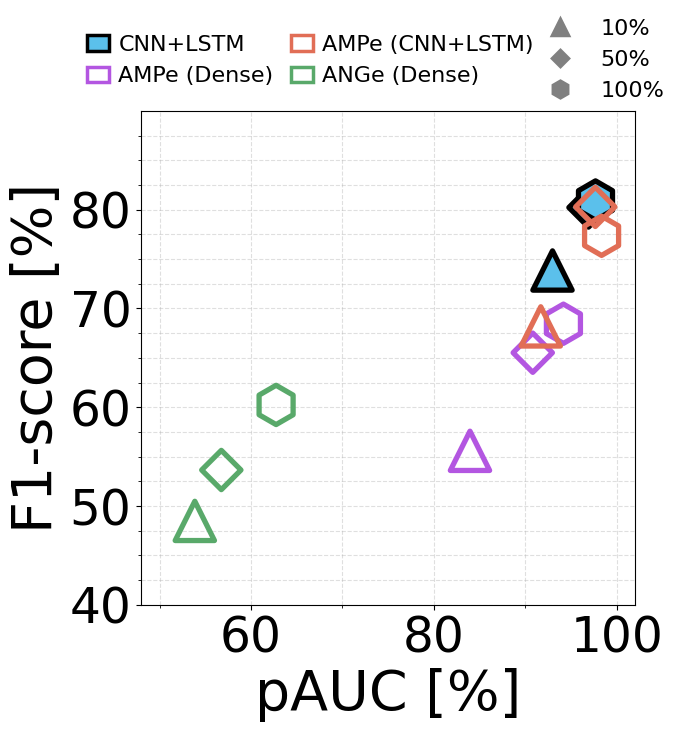

edge-iiot


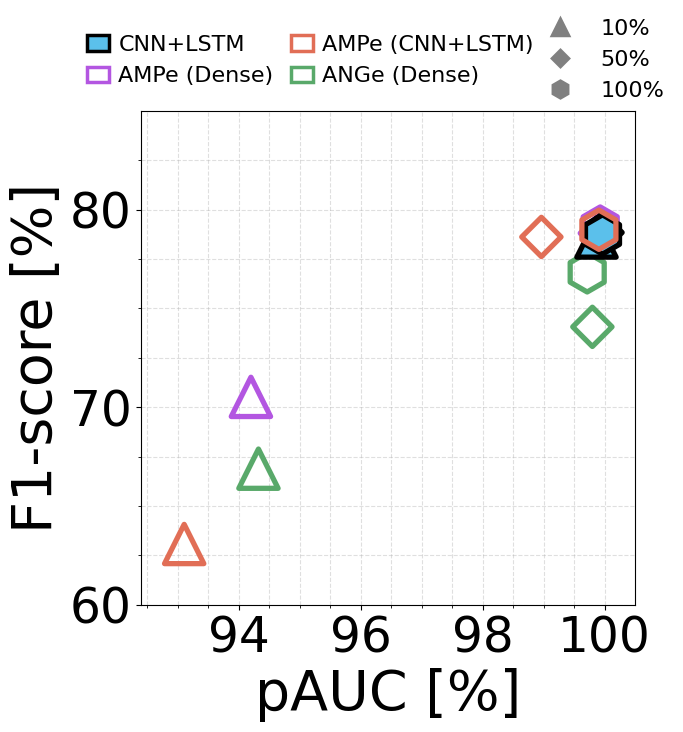

iot-nidd


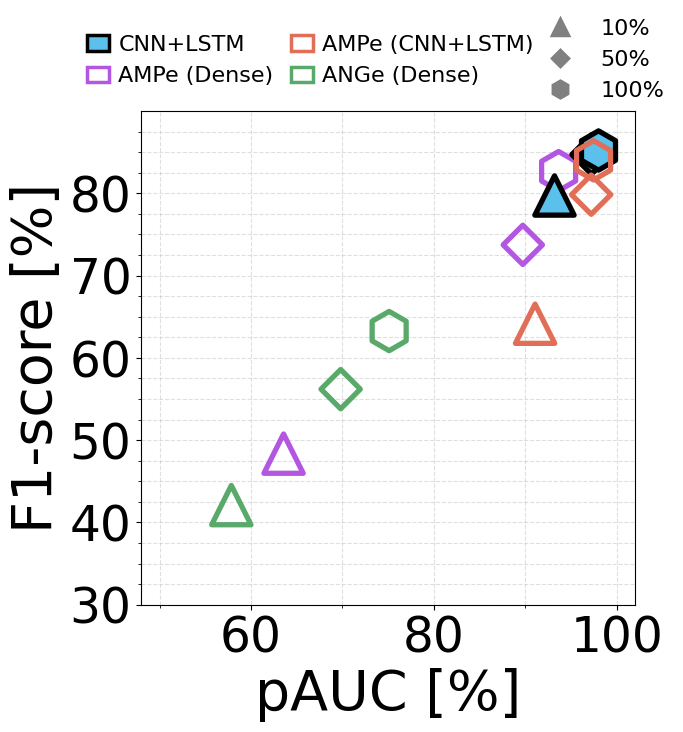

In [9]:
for dataset_name in dss_benign_idx.keys():
    print(dataset_name)
    dataset_df = results_df[results_df['dataset'] == dataset_name]

    model_name_map = {
        'hybrid': 'CNN+LSTM',
        'ampe_fixed_probs': 'AMPe (Dense)',
        'hybrid_ampe_probs': 'AMPe (CNN+LSTM)',
        'ange_probs': 'ANGe (Dense)',
    }

    model_colors = {
        'hybrid':                "#5BC0EB",
        'ampe_fixed_probs':      "#b356e1",
        'hybrid_ampe_probs':     "#e16e56",
        'ange_probs':            "#59A96A",
    }

    perc_markers = {10: 120, 50: 600, 100: 1200}
    markers = {10: '^', 50: 'D', 100: 'h'}

    height_first_leg = 0.98
    height_second_leg = 1.21

    fig, ax = plt.subplots(figsize=(8, 7.5))

    for model, group in dataset_df.groupby('model'):
        for _, row in group.iterrows():
            ax.scatter(
                row['avg_pauc'], row['avg_f1'],
                facecolors='none' if model != 'hybrid' else model_colors[model],
                marker=markers[row['perc']],
                edgecolor=model_colors[model] if model != 'hybrid' else 'black',
                linewidths=3.8,
                s=800 if row['perc'] != 50 else 400,
                zorder=3,
            )

    color_handles = [
        mpatches.Patch(
            facecolor=c if m == 'hybrid' else 'none',
            edgecolor=c if m != 'hybrid' else 'black',
            linewidth=2.5,
            label=model_name_map[m]
        )
        for m, c in model_colors.items()
    ]
    marker_handles = [
        mlines.Line2D([], [], color='gray', marker=mk, linestyle='None', markeredgecolor='gray', markeredgewidth=2.5, markersize=12 if mk!='D' else 8, label=f'{p}%')
        for p, mk in zip([10, 50, 100], ['^', 'D', 'h'])
    ]
    fill_handles = [
        mlines.Line2D([], [], color='gray', marker='o', linestyle='None',
                    markerfacecolor='gray', markeredgecolor='gray',
                    markersize=12, label='DL'),
        mlines.Line2D([], [], color='gray', marker='o', linestyle='None',
                    markerfacecolor='none', markeredgecolor='gray', markeredgewidth=2.5,
                    markersize=12, label='QML'),
    ]

    leg1 = ax.legend(
        handles=color_handles,
        ncols=2,
        loc='lower left',
        bbox_to_anchor=(-0.15, height_first_leg+0.03),
        frameon=False,
        columnspacing=0.8,
        handletextpad=0.4,
        handleheight=0.7,  # vertical size
        handlelength=1.0,  # horizontal size (default 2.0)
        fontsize=16,
    )
    leg3 = ax.legend(
        handles=fill_handles,
        ncols=2,
        bbox_to_anchor=(0.36, height_second_leg),
        frameon=False,
        columnspacing=0.4,
        handletextpad=0.4,
        fontsize=16,
    )
    ax.add_artist(leg1)



    leg2 = ax.legend(
        handles=marker_handles,
        ncols=1,
        loc='lower right',
        bbox_to_anchor=(1.10, height_first_leg),
        frameon=False,
        fontsize=16,
    )
    axis_config = {
        'cic-iomt':  {'x_min': 48, 'x_max': 102, 'y_min': 40, 'y_max': 90, 'x_tick_step': 20, 'y_tick_step': 10, 'x_minor_step': 10, 'y_minor_step': 2.5},
        'edge-iiot':  {'x_min': 92.4, 'x_max': 100.5, 'y_min': 60, 'y_max': 85, 'x_tick_step': 2, 'y_tick_step': 10, 'x_minor_step': 0.5, 'y_minor_step': 2.5},
        'iot-nidd':  {'x_min': 48, 'x_max': 102, 'y_min': 30, 'y_max': 90, 'x_tick_step': 20, 'y_tick_step': 10, 'x_minor_step': 10, 'y_minor_step': 2.5},
    }

    cfg = axis_config[dataset_name]

    ax.set_xlim(cfg['x_min'], cfg['x_max'])
    ax.set_ylim(cfg['y_min'], cfg['y_max'])
    ax.set_aspect((cfg['x_max'] - cfg['x_min']) / (cfg['y_max'] - cfg['y_min']), adjustable='box')
    ax.set_xlabel('pAUC [%]', fontsize=40)
    ax.set_ylabel('F1-score [%]', fontsize=40)

    # then:
    ax.set_xticks(make_ticks(cfg['x_min'], cfg['x_max'], cfg['x_tick_step']))
    ax.set_yticks(make_ticks(cfg['y_min'], cfg['y_max'], cfg['y_tick_step']))
    ax.set_xticks(make_ticks(cfg['x_min'], cfg['x_max'], cfg['x_minor_step']), minor=True)
    ax.set_yticks(make_ticks(cfg['y_min'], cfg['y_max'], cfg['y_minor_step']), minor=True)

    ax.grid(True, which='both', linestyle='--', alpha=0.4)
    ax.tick_params(axis='both', labelsize=35)

    plt.subplots_adjust(top=0.25)
    plt.tight_layout()
    os.makedirs(f"{output_dir}", exist_ok=True)
    plt.savefig(f'{output_dir}/oc1/{dataset_name}_f1_vs_pauc.pdf', dpi=300, bbox_inches='tight', bbox_extra_artists=[leg1, leg2, leg3])#, bbox_extra_artists=[leg1, leg2, leg3]
    plt.savefig(f'{output_dir}/oc1/{dataset_name}_f1_vs_pauc.png', dpi=300, bbox_inches='tight', bbox_extra_artists=[leg1, leg2, leg3])
    plt.show()